# 07 · Naive vs enriched state

Every notebook so far used the **enriched state** $S = (\text{previous token}, \text{line}, \text{syllables so far}, \text{all previous
lines exact})$. Here the policy sees only the **naive state**, the previous word, as a plain bigram does. The environment is unchanged: it
still keeps the full state, computes the same shaped reward from it, and ends lines and poems by the same rules. Only the table the policy
(and the actor-critic's critic) learns is indexed differently. This turns the problem into a POMDP for the agent.

Structure: **setup** (what the naive agent cannot see, and a ceiling on what it can achieve) → **theory check** on the tiny poem MDP of
notebook 06 → **training** (same protocol as notebook 04) → **what the naive policies write** → **discussion**.

In [1]:
import sys, re, json
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from poet import experiments as X, protocol as P, estimators as E, exact as Ex, stats
from poet.estimators import LABELS
from poet.haiku import HaikuMDP, RewardConfig
from poet.policy import TabularSoftmax

plt.rcParams['figure.dpi'] = 110
COLORS = {m: f'C{k}' for k, m in enumerate(P.METHODS)}
lm = X.get_lm()
target = json.load(open(X.RESULTS_DIR / '04_target.json'))
print('naive state of the enriched state (prev=12, line=1, syl=3, exact=1):', X.previous_word((12, 1, 3, 1)))

naive state of the enriched state (prev=12, line=1, syl=3, exact=1): 12


## 1. What the naive agent cannot see

With the naive state, the policy at the start of every line is the same table row $\pi(\cdot\mid\langle s\rangle)$, and after that each
word depends only on the previous word. The agent knows neither which line it is writing nor how many syllables it has written. Two
consequences:

- **The initial policy is the same.** $\theta_0 = \tau\log P_{\text{bigram}}$ depends only on the previous word anyway. The bigram *is* a
  naive policy, and both runs start from it. What differs is what can be learned: about 500 rows instead of tens of thousands.
- **There is a ceiling on the valid rate.** The three lines all start from $\langle s\rangle$ and share no memory, so under *any* naive
  policy they are independent and identically distributed. If a line has exactly 5 syllables with probability $x$ and exactly 7 with
  probability $y$, then $P(\text{valid}) = x^2y$ with $x + y \le 1$. The maximum is at $x = 2/3$, $y = 1/3$:
  $$P(\text{valid}) \le \max_{x+y\le1} x^2y = \tfrac{4}{27} \approx 0.148 .$$
  The 0.8 valid-rate target of notebook 04 is out of reach by construction, whatever the algorithm.

In [2]:
x = np.linspace(0, 1, 100_001)
f = x ** 2 * (1 - x)
print(f'max x^2 (1 - x) = {f.max():.4f} at x = {x[f.argmax()]:.4f}   (4/27 = {4 / 27:.4f})')
VALID_CEILING = 4 / 27

max x^2 (1 - x) = 0.1481 at x = 0.6667   (4/27 = 0.1481)


## 2. Theory check on the tiny poem MDP

The tiny MDP of notebook 06 (words *sea* and *ocean*, lines of 1-2-1 syllables, the shaped reward with KL), now with a naive policy: one
table row per previous token, 3 rows in total. As in notebook 06 we enumerate all poems and all batches of 2, and compare the exact mean of
each estimator with the finite-difference gradient.

What we expect:
- **The policy-gradient estimators stay unbiased.** Their proofs use the Markov property of the *environment*, whose
  state is still the full one. They only need the score to have zero mean given the history, which holds for any policy, including one
  that ignores most of the state. This is a known advantage of policy gradient: actor-only methods suffer less from violations of the
  Markov assumption, since they do not exploit it directly.
- **A critic on the naive state is biased**, even the best one. The TD advantage $r + V(S') - V(S)$ is an advantage only if $V$ is the value
  of the state. A table indexed by the previous word can at best store the average value of all the states that share that word (the
  *aliased* value). The actor-critic relies on its critic, so this is where the naive state should hurt it.

In [3]:
tiny = HaikuMDP(Ex.restrict_bigram(lm, ['sea', 'ocean']), RewardConfig(), targets=(1, 2, 1), tolerance=0)
T, nA = tiny.horizon, tiny.n_actions
print(f'{"policy":9s} {"estimator (n = 2)":32s} {"relative bias":>14s} {"tr Cov":>8s}')
for state, key in [('enriched', None), ('naive', X.previous_word)]:
    pol = TabularSoftmax(tiny.bigram_logits(1.0), 1.0, key)
    trajs, probs = Ex.enumerate_trajectories(tiny, pol)
    index = Ex.state_index(trajs, key)
    rng = np.random.default_rng(0)
    for k in index:
        pol.theta[k][:] += rng.normal(0.0, 1.0, nA)          # a generic theta, as in notebook 06
    trajs, probs = Ex.enumerate_trajectories(tiny, pol)
    fd = Ex.finite_difference_gradient(tiny, pol, index)
    V_full = Ex.value_function(tiny, pol)
    V_alias = Ex.aliased_value(trajs, probs, X.previous_word)
    candidates = {
        'REINFORCE':                         lambda b: E.estimate('reinforce', b, 1.0, T),
        'REINFORCE + b':                     lambda b: E.estimate('reinforce_b', b, 1.0, T),
        'GPOMDP':                            lambda b: E.estimate('gpomdp', b, 1.0, T),
        'GPOMDP + b_t':                      lambda b: E.estimate('gpomdp_b', b, 1.0, T),
        'TD advantage, V^pi (full state)':   lambda b: E.td_advantage(b, 1.0, V_full),
        'TD advantage, V(previous word)':    lambda b: E.td_advantage(b, 1.0, V_alias),
    }
    print(f'{state} policy: {len(index)} table rows')
    for name, est in candidates.items():
        mean, var = Ex.pair_moments(est, trajs, probs, index, nA, key)
        print(f'{"":9s} {name:32s} {np.linalg.norm(mean - fd) / np.linalg.norm(fd):14.1e} {var:8.2f}')

policy    estimator (n = 2)                 relative bias   tr Cov


enriched policy: 14 table rows


          REINFORCE                               1.2e-10    53.96


          REINFORCE + b                           1.2e-10    53.60


          GPOMDP                                  1.2e-10    34.11


...

          REINFORCE + b                           1.9e-10    44.66


          GPOMDP                                  1.9e-10    17.81


          GPOMDP + b_t                            1.9e-10    36.42


          TD advantage, V^pi (full state)         1.9e-10     9.74


          TD advantage, V(previous word)          2.6e-01     9.45


The four policy-gradient estimators are unbiased for both policies (relative error ~$10^{-10}$, the finite-difference error). The TD
advantage is unbiased with the full-state value $V^\pi$, even for the naive actor. With the best critic that only sees the previous word it
is biased, for both actors. So the bias comes from what the *critic* sees, not from what the actor sees.

## 3. Training with the naive state

Same protocol as notebook 04: shaped reward, budget $10^5$ episodes, the grid of notebook 04 extended for all methods when a best α is at
an edge, 3 tuning seeds, then 10 fresh final seeds. The tuning criterion (mean evaluation return over the budget) does not need a reachable
target. Unlike the sparse rewards of notebook 05, the scores here are not flat, so we use notebook 04's plain edge rule.

In [4]:
GRID0 = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
TUNE_CACHE, FINAL_CACHE = X.RESULTS_DIR / '07_tuning.pkl', X.RESULTS_DIR / '07_final.pkl'
grid = list(GRID0)
while True:
    specs = [P.spec(m, a, s, state='naive') for m in P.METHODS for a in grid for s in P.TUNE_SEEDS]
    res = X.run_many(specs, TUNE_CACHE, verbose=False)
    scores = {}
    for sp, r in zip(specs, res):
        scores.setdefault((sp['method'], sp['alpha']), []).append(P.tuning_score(r))
    best, _ = P.best_alphas(scores, grid, P.METHODS, {m: True for m in P.METHODS})
    new = P.extend_grid(grid, best)
    if new == grid:
        break
    print(f'best alpha at a grid edge {best} -> extending the grid to {new}')
    grid = new
best04 = {'reinforce': 3.0, 'reinforce_b': 3.0, 'gpomdp': 3.0, 'gpomdp_b': 3.0, 'ac': 1.0}
print('naive state: mean evaluation return over the budget (3 seeds)')
print(f'{"method":24s}' + ''.join(f'{a:>8}' for a in grid))
for m in P.METHODS:
    print(f'{LABELS[m]:24s}' + ''.join(f'{np.mean(scores[(m, a)]):8.2f}' for a in grid) + f'   best alpha = {best[m]}  (enriched: {best04[m]})')

naive state: mean evaluation return over the budget (3 seeds)
method                      0.01    0.03     0.1     0.3     1.0     3.0    10.0
REINFORCE                   5.59    6.80    8.19   10.94   17.00   11.31    8.30   best alpha = 1.0  (enriched: 3.0)
REINFORCE + baseline        5.58    6.81    8.11   10.04   15.49   19.51   10.31   best alpha = 3.0  (enriched: 3.0)
GPOMDP                      5.58    6.80    8.11    9.92   14.83   19.10    9.27   best alpha = 3.0  (enriched: 3.0)
GPOMDP + baseline b_t       5.58    6.78    8.10    9.60   14.52   19.55   17.28   best alpha = 3.0  (enriched: 3.0)
Actor-critic                8.53   11.59   18.91    4.98    3.56   11.23    9.96   best alpha = 0.1  (enriched: 1.0)


all 50 runs loaded from 07_final.pkl


all 50 runs loaded from 04_final.pkl


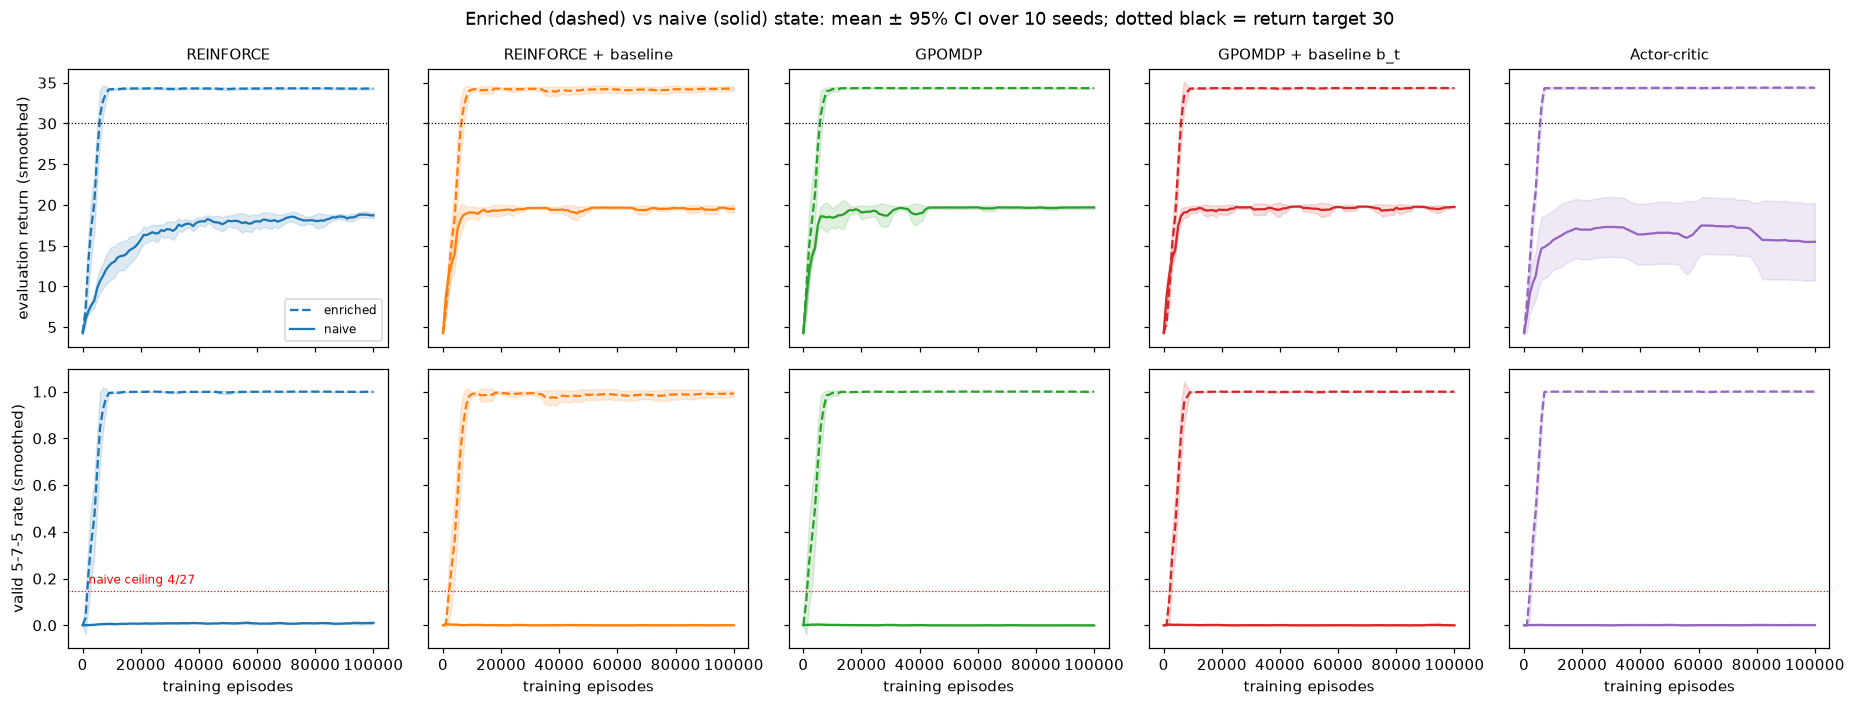

In [5]:
final = {'naive': X.run_many([P.spec(m, best[m], s, state='naive') for m in P.METHODS for s in P.FINAL_SEEDS], FINAL_CACHE),
         'enriched': X.run_many([P.spec(m, best04[m], s) for m in P.METHODS for s in P.FINAL_SEEDS], X.RESULTS_DIR / '04_final.pkl')}
final = {st: {m: final[st][k * 10:(k + 1) * 10] for k, m in enumerate(P.METHODS)} for st in final}
xs = np.array(final['naive']['reinforce'][0]['history']['eval_episodes'])

fig, axes = plt.subplots(2, 5, figsize=(17, 6.5), sharex=True, sharey='row')
for j, m in enumerate(P.METHODS):
    for st, ls in [('enriched', '--'), ('naive', '-')]:
        for i, key in enumerate(['return', 'valid']):
            ys = np.array([P.smoothed(r['history'], key) for r in final[st][m]])
            mean, hw = stats.mean_ci(ys)
            axes[i, j].plot(xs, mean, ls, color=COLORS[m], label=st)
            axes[i, j].fill_between(xs, mean - hw, mean + hw, color=COLORS[m], alpha=0.15)
    axes[0, j].set_title(LABELS[m], fontsize=10)
    axes[0, j].axhline(target['return_target'], color='k', lw=0.8, ls=':')
    axes[1, j].axhline(VALID_CEILING, color='r', lw=0.8, ls=':')
    axes[1, j].set_xlabel('training episodes')
axes[0, 0].set_ylabel('evaluation return (smoothed)'); axes[1, 0].set_ylabel('valid 5-7-5 rate (smoothed)')
axes[0, 0].legend(fontsize=8); axes[1, 0].text(2000, VALID_CEILING + 0.03, 'naive ceiling 4/27', color='r', fontsize=8)
fig.suptitle('Enriched (dashed) vs naive (solid) state: mean ± 95% CI over 10 seeds; dotted black = return target 30')
plt.tight_layout(); plt.show()

In [6]:
def summary(rs):
    fm = lambda c: [r['final_metrics'][c] for r in rs]
    sc = [P.sample_complexity(r['history'], target['return_target']) for r in rs]
    return {'return': stats.mean_ci(fm('return')), 'valid': np.mean(fm('valid')), 'distinct': np.mean(fm('distinct_poems')), 'words': np.mean(fm('distinct_words')),
            'rows': np.mean([r['n_states'] for r in rs]), 'reached': sum(v is not None for v in sc),
            'mean_eval': np.mean([P.tuning_score(r) for r in rs])}

print(f'{"method":24s} {"state":9s} {"final return":>16s} {"valid":>7s} {"distinct":>9s} {"words":>6s} {"table rows":>11s} {"reached 30":>11s} {"mean return":>12s}')
for m in P.METHODS:
    for st in ['enriched', 'naive']:
        s = summary(final[st][m])
        print(f'{LABELS[m]:24s} {st:9s} {s["return"][0]:9.1f} ± {s["return"][1]:4.1f} {s["valid"]:7.3f} {s["distinct"]:9.2f} {s["words"]:6.2f} '
              f'{s["rows"]:11,.0f} {s["reached"]:8d}/10 {s["mean_eval"]:12.1f}')
print('final metrics on 200 fresh poems after 100k episodes; words = share of the vocabulary used; "mean return" = mean evaluation return over the whole budget')

method                   state         final return   valid  distinct  words  table rows  reached 30  mean return
REINFORCE                enriched       34.3 ±  0.1   1.000      0.01   0.03       9,635       10/10         33.6
REINFORCE                naive          19.1 ±  0.4   0.008      0.53   0.21         501        0/10         16.9
REINFORCE + baseline     enriched       34.3 ±  0.3   0.992      0.17   0.11      10,628       10/10         33.4
REINFORCE + baseline     naive          19.7 ±  0.1   0.000      0.08   0.02         501        0/10         19.2
GPOMDP                   enriched       34.3 ±  0.1   1.000      0.00   0.02       9,706       10/10         33.7
GPOMDP                   naive          19.7 ±  0.2   0.000      0.00   0.01         501        0/10         19.2
GPOMDP + baseline b_t    enriched       34.3 ±  0.0   1.000      0.03   0.03      10,687       10/10         33.6
GPOMDP + baseline b_t    naive          19.7 ±  0.1   0.000      0.16   0.02         501

## 4. What the naive policies write

If the argument of §1 is right, a naive policy has the same distribution of line lengths at all three positions, and its best compromise
mixes 5- and 7-syllable lines. Below we look at the syllable counts of the 200 final poems of each run, by line position.

In [7]:
def line_lengths(r):
    counts = []                                  # one row per poem: syllables of lines 1, 2, 3
    for poem, n in r['final_poems']:
        counts += [list(map(int, re.findall(r'\((\d+)\)', poem)))] * n
    return np.array(counts)

print(f'{"method":24s} {"state":9s}' + ''.join(f'{"line " + str(i + 1) + ": P(5) P(7)":>21s}' for i in range(3)))
for m in P.METHODS:
    for st in ['enriched', 'naive']:
        L = np.concatenate([line_lengths(r) for r in final[st][m]])
        print(f'{LABELS[m]:24s} {st:9s}' + ''.join(f'{np.mean(L[:, i] == 5):14.2f} {np.mean(L[:, i] == 7):5.2f}' for i in range(3)))
print('(pooled over the 10 final seeds x 200 poems; the naive optimum for the valid rate is P(5) = 2/3, P(7) = 1/3 on every line)')

method                   state        line 1: P(5) P(7)    line 2: P(5) P(7)    line 3: P(5) P(7)
REINFORCE                enriched           1.00  0.00          0.00  1.00          1.00  0.00
REINFORCE                naive              0.93  0.01          0.92  0.01          0.92  0.01
REINFORCE + baseline     enriched           1.00  0.00          0.00  0.99          1.00  0.00
REINFORCE + baseline     naive              1.00  0.00          1.00  0.00          1.00  0.00
GPOMDP                   enriched           1.00  0.00          0.00  1.00          1.00  0.00
GPOMDP                   naive              1.00  0.00          1.00  0.00          1.00  0.00
GPOMDP + baseline b_t    enriched           1.00  0.00          0.00  1.00          1.00  0.00
GPOMDP + baseline b_t    naive              1.00  0.00          0.99  0.00          1.00  0.00
Actor-critic             enriched           1.00  0.00          0.00  1.00          1.00  0.00
Actor-critic             naive              0.6

**Why the naive policies do not even approach the 4/27 ceiling.** The ceiling is for the *valid rate*, but the agent maximises the
*return*. Take a naive policy whose lines have exactly 5 syllables with probability $x$ and exactly 7 otherwise. Count only the syllable
terms and the bonuses, which dominate the shaped reward (by notebook 03, a line ending at $k$ syllables earns $t - |t - k|$ in progress
plus 3 if $k = t$):
- a 5-syllable line scores 8 at a 5-target and 5 at the 7-target;
- a 7-syllable line scores 3 at a 5-target and 10 at the 7-target;
- the completion bonus 10 is paid with probability $x^2(1-x)$.

In [8]:
def naive_return(x):
    line5 = 8 * x + 3 * (1 - x)           # lines 1 and 3 (target 5)
    line7 = 5 * x + 10 * (1 - x)          # line 2 (target 7)
    return 2 * line5 + line7 + 10 * x ** 2 * (1 - x)
xs_ = np.linspace(0, 1, 10_001)
best_x = xs_[np.argmax(naive_return(xs_))]
for label, x_ in [('always 5 syllables (x = 1)', 1.0), ('valid-rate optimum (x = 2/3)', 2 / 3), (f'return optimum (x = {best_x:.2f})', best_x)]:
    print(f'{label:32s} return (syllables + bonuses) = {naive_return(x_):5.2f}   valid rate = {x_ ** 2 * (1 - x_):.3f}')

always 5 syllables (x = 1)       return (syllables + bonuses) = 21.00   valid rate = 0.000
valid-rate optimum (x = 2/3)     return (syllables + bonuses) = 20.81   valid rate = 0.148
return optimum (x = 0.86)        return (syllables + bonuses) = 21.34   valid rate = 0.103


In [9]:
print('Most frequent final poem of the first three seeds, naive state:')
for m in P.METHODS:
    for r in final['naive'][m][:3]:
        top = r['final_poems'][0]
        print(f"  {LABELS[m]:24s} seed {r['spec']['seed']}: {top[1]:3d}/200  {top[0]}")

Most frequent final poem of the first three seeds, naive state:
  REINFORCE                seed 100: 121/200  and every side (5) / and every side (5) / and every side (5)
  REINFORCE                seed 101:  72/200  ulysses began (5) / ulysses began (5) / ulysses began (5)
  REINFORCE                seed 102:  53/200  so many a god (5) / so many a god (5) / so many a god (5)
  REINFORCE + baseline     seed 100: 200/200  great achilles hand (5) / great achilles hand (5) / great achilles hand (5)
  REINFORCE + baseline     seed 101: 200/200  now every side (5) / now every side (5) / now every side (5)
  REINFORCE + baseline     seed 102:  36/200  there daughter of war (5) / there daughter of war (5) / there daughter of war (5)
  GPOMDP                   seed 100: 200/200  fierce achilles mind (5) / fierce achilles mind (5) / fierce achilles mind (5)
  GPOMDP                   seed 101: 200/200  give no more the war (5) / give no more the war (5) / give no more the war (5)
  GPOMDP      

## 5. Discussion

**With the naive state, no method writes haiku.** All five methods start from the same bigram and reach the return target 30 in 10/10
runs with the enriched state. With the naive state they reach it in 0/10. The final return is 19.1–19.7 for the batch methods and 15.7 for
the actor-critic, against 34.3–34.4 with the enriched state. The valid rate is 0–0.8%, against 99–100%. Almost every naive run converges
to the same kind of poem: **one 5-syllable line written three times** ("the sons of heaven / the sons of heaven / the sons of heaven").
This poem earns the exact-line bonus on lines 1 and 3, and on line 2 it is two syllables short.

**This is a property of the representation, not of the algorithms.** Three observations support that:
- **Same distribution at every line.** The line-length distribution of each naive policy is the same at the three positions (e.g.
  REINFORCE: 93%, 92% and 92% five-syllable lines; actor-critic: 69% at each). This is the i.i.d.-lines property of §1: a policy that
  only sees the previous word cannot know that the second line should be longer.
- **A provable ceiling.** The valid rate is at most 4/27 ≈ 0.148 for *any* naive policy.
- **The return barely rewards approaching that ceiling.** Counting syllable terms and bonuses only, the always-5 policy scores 21.0,
  the valid-rate optimum (x = 2/3) scores 20.8, and the best naive return is only 21.3, at x ≈ 0.86 with a 10% valid rate. The batch
  methods reach the always-5 corner, whose observed return 19.7 equals 21 minus the fluency term. Leaving it would mean putting about
  14% probability on a first word that starts a 7-syllable line, for a gain of about 0.3. In a near-deterministic softmax, the gradient
  towards that mixture is tiny.

So the enriched state is not a convenience. The line index and the syllable count are exactly what a policy needs in order to write
lines of *different* lengths, and the "previous lines exact" flag keeps the completion bonus Markov (notebook 03).

**Policy gradient tolerates the aliasing; the critic does not.** On the tiny MDP the four policy-gradient estimators stay exactly unbiased
for the naive policy. Their proofs only use the Markov property of the environment's state, a known strength of actor-only methods.
The TD advantage is unbiased only if its critic sees the full state. The best critic on the previous word is 26% biased for the naive
actor, and 56% biased for the enriched one. In training this is visible in the actor-critic:
- it is the only naive method with a large spread across seeds (final return 15.7 ± 4.8);
- its best step size drops to α = 0.1, from α = 1 with the enriched state;
- its tuning profile collapses for α ≥ 0.3 (mean return 3.6–11.2), while the batch methods still work at α = 3.

The batch methods have the opposite problem. Their gradient is correct, but the best policy in the naive class is poor.

**Smaller table, not faster learning.** The naive table has 501 rows, against about 10 000 visited rows for the enriched one. One might
expect sharing across lines to speed up learning. It does not: in the first 5 000 episodes the naive curves rise more slowly than the
enriched ones, and the batch methods with a baseline and GPOMDP level off at about 19.5 by roughly 10 000 episodes, while the enriched
curves reach 34. Generalising across states only
helps when the states it merges should behave alike, and here they are exactly the states (line 1 vs line 2, 2 vs 4 syllables written)
that must behave differently.

**Diversity.** The naive REINFORCE runs keep the most distinct poems (53% of 200), because REINFORCE at its tuned α = 1 never becomes fully
deterministic. The same lack of commitment also costs it return (19.1 vs 19.7). The other naive methods, like all the enriched ones,
mostly settle on one poem. This memorisation is common to every reward and state we tried that has no explicit diversity term.